# Рекомендации фильмов — HSE RecSys Challenge 2026

По истории оценок формируем **10 рекомендаций для каждого пользователя**.
Метрика соревнования — **Recall@10**. Проверены популярность, ItemKNN, EASE и SASRec.
**Финальная модель — SASRec; полученный результат на Kaggle — 0,2847.**

Весь код и параметры находятся в этой тетрадке. Внешние Python-файлы и конфигурационные файлы не нужны.
Для запуска в Kaggle подключите данные соревнования, включите **GPU** и **Internet**, затем выполните
**Restart Kernel and Run All**. Локально четыре CSV можно положить в `data/` рядом с тетрадкой.
Веса, история обучения и финальный CSV сохраняются в `outputs/`.

## 1. Параметры и окружение

Сохраняем параметры завершённого эксперимента: seed = 42, 100 событий в окне SASRec,
64 признака, 2 блока, 2 attention-heads, dropout = 0,2. Для выбора эпохи допускается до 50 эпох
с ранней остановкой. В исходном запуске была выбрана **48-я эпоха**.

Исходный GPU-запуск использовал Tesla T4, Python 3.13.15, PyTorch 2.11.0+cu128 и RePlay 0.22.0.
Текущие версии записываются в результаты запуска. Установку зависимостей RePlay выполняет раздел SASRec;
предустановленный CUDA PyTorch не заменяется.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import platform
import random
import time
import zipfile

import numpy as np
import pandas as pd
from scipy import sparse, linalg
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA_DIR = None  # Автопоиск; при необходимости укажите Path('/kaggle/input/...').
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = {'seed': 42,
 'k': 10,
 'validation_fraction': 0.2,
 'train_min_rating': None,
 'target_min_rating': None,
 'exclude_seen': True,
 'knn_neighbors': 100,
 'knn_shrinkage': 10.0,
 'batch_size': 256,
 'ease_regularization_grid': [100.0, 300.0, 1000.0, 3000.0, 10000.0],
 'blas_threads': 4,
 'sasrec': {'max_sequence_length': 100,
            'window_stride': 50,
            'embedding_dim': 64,
            'num_heads': 2,
            'num_blocks': 2,
            'dropout': 0.2,
            'batch_size': 128,
            'prediction_batch_size': 256,
            'learning_rate': 0.001,
            'weight_decay': 1e-05,
            'max_epochs': 50,
            'patience': 8,
            'gradient_clip': 1.0,
            'mixed_precision': True,
            'require_cuda': True,
            'num_workers': 0}}

SEED, K = CONFIG['seed'], CONFIG['k']
random.seed(SEED)
np.random.seed(SEED)
pd.set_option('display.max_colwidth', 100)
VERSIONS = {
    'python': platform.python_version(),
    **{name: metadata.version(name) for name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'threadpoolctl']},
}

## 2. Данные

`events.csv` содержит историю оценок, `user_features.csv` — признаки пользователей,
`item_features.csv` — каталог и жанры фильмов, `submission_sample.csv` — формат ответа.
ID читаются как строки. В текущих моделях используются только взаимодействия;
пол, возраст и жанры в обучение не включаются.

In [2]:
FILENAMES = ['events.csv', 'user_features.csv', 'item_features.csv', 'submission_sample.csv']


def resolve_data_dir(explicit=None):
    if explicit is not None:
        candidate = Path(explicit).expanduser()
        if not all((candidate / f).is_file() for f in FILENAMES):
            raise FileNotFoundError(f'В {candidate} должны находиться все четыре CSV: {FILENAMES}')
        return candidate.resolve()
    candidates = [Path('data'), Path('.'), Path('upload'), Path('../upload')]
    if Path('/kaggle/input').exists():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('events.csv')]
    matches = sorted({p.resolve() for p in candidates if all((p / f).is_file() for f in FILENAMES)})
    if len(matches) != 1:
        raise FileNotFoundError(f'Найдено папок с данными: {len(matches)}. Укажите DATA_DIR явно: {matches}')
    return matches[0]

DATA_DIR = resolve_data_dir(DATA_DIR)
events = pd.read_csv(DATA_DIR / 'events.csv', dtype={'user_id': str, 'item_id': str})
user_features = pd.read_csv(DATA_DIR / 'user_features.csv', dtype={'user_id': str})
item_features = pd.read_csv(DATA_DIR / 'item_features.csv', dtype={'item_id': str})
sample = pd.read_csv(DATA_DIR / 'submission_sample.csv', dtype={'user_id': str, 'item_id': str})


def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

DATA_HASHES = {name: file_sha256(DATA_DIR / name) for name in FILENAMES}
user_counts = events.groupby('user_id').size()
item_counts = events.groupby('item_id').size()
display(pd.Series({
    'События': len(events), 'Пользователи': len(user_features),
    'Фильмы в каталоге': len(item_features), 'Фильмы с историей': events['item_id'].nunique(),
    'Минимум событий на пользователя': user_counts.min(), 'Медиана длины истории': user_counts.median(),
}, name='Значение').to_frame())
display(events.head())

,Значение
События,894149.0
Пользователи,6040.0
Фильмы в каталоге,3706.0
Фильмы с историей,3690.0
Минимум событий на пользователя,14.0
Медиана длины истории,84.5


,user_id,item_id,rating,timestamp
0,0,1505,4,0
1,0,3669,3,1
2,0,584,4,2
3,0,3390,3,3
4,0,2885,4,4


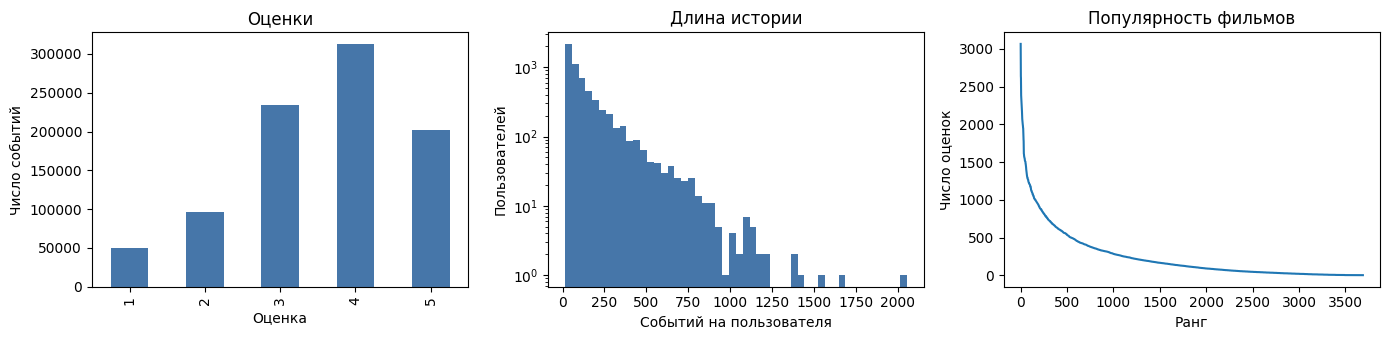

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
events['rating'].value_counts().sort_index().plot.bar(ax=axes[0], color='#4676a9')
axes[0].set(title='Оценки', xlabel='Оценка', ylabel='Число событий')
axes[1].hist(user_counts, bins=50, color='#4676a9')
axes[1].set(title='Длина истории', xlabel='Событий на пользователя', ylabel='Пользователей', yscale='log')
axes[2].plot(np.sort(item_counts.to_numpy())[::-1])
axes[2].set(title='Популярность фильмов', xlabel='Ранг', ylabel='Число оценок')
plt.tight_layout()
plt.show()

В данных 894 149 событий, 6 040 пользователей и 3 706 фильмов, из которых 3 690 имеют историю.
Минимальная длина истории — 14, медиана — 84,5. Популярность распределена неравномерно.
`timestamp` используется только для порядка событий внутри пользователя: его значения похожи
на позиции в истории, поэтому они не трактуются как глобальное Unix-время.

## 3. Локальная валидация и Recall@10

Для каждого пользователя откладываем последние 20% событий, округляя вверх.
Обучающие статистики рассчитываются только по оставшейся истории. По умолчанию любая отложенная оценка
считается целевым взаимодействием, а train-матрица отражает бинарный факт взаимодействия.

$$Recall@10(u)=\frac{|Top10(u)\cap Target(u)|}{|Target(u)|}.$$

Усредняем по пользователям с непустым target. Оценка использует весь каталог, без выборки негативов.
Уже встречавшиеся фильмы исключаются по **всей** известной истории, включая низкие оценки.
Это локальная схема проверки; разбиение скрытого теста организаторов может отличаться.

In [4]:
def split_user_tail(frame, fraction):
    ordered = frame.sort_values(['user_id', 'timestamp'], kind='stable').copy()
    size = ordered.groupby('user_id')['item_id'].transform('size')
    if (size < 2).any():
        raise ValueError('Для этого разбиения нужно хотя бы два события на пользователя')
    tail_size = np.ceil(size * fraction).astype(int).clip(lower=1)
    tail_size = np.minimum(tail_size, size - 1)
    position = ordered.groupby('user_id').cumcount()
    is_validation = position >= (size - tail_size)
    return ordered.loc[~is_validation].copy(), ordered.loc[is_validation].copy()

def relevant(frame, min_rating):
    return frame.copy() if min_rating is None else frame.loc[frame['rating'] >= min_rating].copy()

def recall_at_k(recommendations, ground_truth, k=10):
    rows = []
    for user_id, true_items in ground_truth.items():
        if not true_items:
            continue
        predicted = recommendations.get(user_id, [])[:k]
        if len(predicted) != len(set(predicted)):
            raise ValueError(f'Повторные рекомендации для {user_id}')
        hits = len(set(predicted) & set(true_items))
        rows.append((user_id, hits, len(true_items), hits / len(true_items)))
    per_user = pd.DataFrame(rows, columns=['user_id', 'hits', 'target_count', 'recall'])
    if per_user.empty:
        raise ValueError('Нет пользователей с непустым target')
    return float(per_user['recall'].mean()), per_user

train_raw, valid_raw = split_user_tail(events, CONFIG['validation_fraction'])
train = relevant(train_raw, CONFIG['train_min_rating'])
valid = relevant(valid_raw, CONFIG['target_min_rating'])
targets = valid.groupby('user_id')['item_id'].agg(set).to_dict()
validation_users = sorted(targets)
display(pd.DataFrame({
    'Часть': ['Train', 'Validation'],
    'События': [len(train), len(valid)],
    'Пользователи': [train['user_id'].nunique(), valid['user_id'].nunique()],
}))

,Часть,События,Пользователи
0,Train,712916,6040
1,Validation,181233,6040


## 4. Общие функции ранжирования

Создаём разреженную матрицу пользователь–фильм. Строковые ID переводятся во внутренние индексы,
а при экспорте возвращаются исходные значения. Во всех экспериментах используются одни и те же
фильтрация просмотренного и правила выбора top-10.

In [5]:
user_ids = np.array(sorted(user_features['user_id'].unique()), dtype=object)
item_ids = np.array(sorted(item_features['item_id'].unique()), dtype=object)
user_to_idx = {value: index for index, value in enumerate(user_ids)}
item_to_idx = {value: index for index, value in enumerate(item_ids)}
N_USERS, N_ITEMS = len(user_ids), len(item_ids)


def interaction_matrix(frame):
    rows = frame['user_id'].map(user_to_idx)
    cols = frame['item_id'].map(item_to_idx)
    matrix = sparse.csr_matrix(
        (np.ones(len(frame), dtype=np.float32),
         (rows.to_numpy(dtype=np.int32), cols.to_numpy(dtype=np.int32))),
        shape=(N_USERS, N_ITEMS), dtype=np.float32,
    )
    matrix.sum_duplicates()
    matrix.data[:] = 1.0
    return matrix

def popularity_scores(matrix):
    return np.asarray(matrix.sum(axis=0)).ravel().astype(np.float32)

def top_k_items(scores, popularity, seen_indices, k):
    allowed = np.ones(N_ITEMS, dtype=bool)
    if CONFIG['exclude_seen']:
        allowed[seen_indices] = False
    candidate_idx = np.flatnonzero(allowed)
    if len(candidate_idx) < k:
        raise ValueError('Недостаточно допустимых фильмов для top-k')
    order = np.lexsort((candidate_idx, -popularity[candidate_idx], -scores[candidate_idx]))
    return item_ids[candidate_idx[order[:k]]].tolist()

def recommend(model_name, matrix, seen, popularity, requested_users, similarity=None):
    result = {}
    requested_users = list(requested_users)
    for start in range(0, len(requested_users), CONFIG['batch_size']):
        batch_users = requested_users[start:start + CONFIG['batch_size']]
        batch_idx = np.array([user_to_idx[u] for u in batch_users])
        if model_name == 'itemknn' or model_name.startswith('ease_l2_'):
            if similarity is None:
                raise ValueError('Нужна обученная матрица весов')
            product = matrix[batch_idx] @ similarity
            batch_scores = product.toarray() if sparse.issparse(product) else np.asarray(product)
        elif model_name == 'popularity':
            batch_scores = np.broadcast_to(popularity, (len(batch_idx), N_ITEMS))
        else:
            raise ValueError(f'Неизвестная модель: {model_name}')
        for offset, (user_id, index) in enumerate(zip(batch_users, batch_idx)):
            seen_indices = seen.indices[seen.indptr[index]:seen.indptr[index + 1]]
            result[user_id] = top_k_items(batch_scores[offset], popularity, seen_indices, K)
    return result

train_matrix = interaction_matrix(train)
seen_matrix = interaction_matrix(train_raw)
popularity = popularity_scores(train_matrix)
experiment_rows = []

def register_validation(name, hypothesis, prediction, seconds, parameters=None):
    score, _ = recall_at_k(prediction, targets, K)
    row = {
        'model': name, 'hypothesis': hypothesis, 'local_recall_at_10': score,
        'parameters': json.dumps(parameters or {}, ensure_ascii=False, sort_keys=True),
        'elapsed_seconds': round(seconds, 3),
    }
    experiment_rows[:] = [old for old in experiment_rows if old['model'] != name]
    experiment_rows.append(row)
    print(f'{name}: Recall@10 = {score:.6f}; {seconds:.1f} с')
    return score

## 5. H0 — популярность

**Предположение:** самые популярные фильмы дают рабочую точку отсчёта.
Рекомендуем фильмы с наибольшим числом взаимодействий в train, исключая известную историю пользователя.

In [6]:
started = time.perf_counter()
pop_prediction = recommend('popularity', train_matrix, seen_matrix, popularity, validation_users)
pop_score = register_validation('popularity', 'H0: популярность как точка отсчёта',
                                pop_prediction, time.perf_counter() - started)

popularity: Recall@10 = 0.036167; 1.7 с


## 6. H1 — ItemKNN

**Предположение:** сходство фильмов по общим пользователям улучшает персонализацию.
Используем cosine similarity со shrinkage = 10, оставляем 100 соседей каждого фильма.
Score кандидата — сумма сходств с фильмами из истории.

$$s_{ij}=\frac{C_{ij}}{\sqrt{n_i n_j}}\frac{C_{ij}}{C_{ij}+10},\quad C=X^TX,\quad s_{ii}=0.$$

In [7]:
def fit_itemknn(matrix, neighbors=100, shrinkage=10.0, batch_size=256):
    if neighbors < 1 or shrinkage < 0:
        raise ValueError('neighbors >= 1, shrinkage >= 0')
    counts = np.asarray(matrix.sum(axis=0)).ravel()
    blocks = []
    for start in range(0, N_ITEMS, batch_size):
        stop = min(start + batch_size, N_ITEMS)
        cooccurrence = (matrix[:, start:stop].T @ matrix).tocoo()
        absolute_rows = cooccurrence.row + start
        denominator = np.sqrt(counts[absolute_rows] * counts[cooccurrence.col])
        values = np.divide(cooccurrence.data, denominator,
                           out=np.zeros_like(cooccurrence.data), where=denominator > 0)
        if shrinkage:
            values *= cooccurrence.data / (cooccurrence.data + shrinkage)
        values[absolute_rows == cooccurrence.col] = 0
        similarity_block = sparse.csr_matrix(
            (values, (cooccurrence.row, cooccurrence.col)), shape=(stop - start, N_ITEMS)
        )
        similarity_block.eliminate_zeros()
        for row in range(stop - start):
            lo, hi = similarity_block.indptr[row:row + 2]
            row_values = similarity_block.data[lo:hi]
            row_indices = similarity_block.indices[lo:hi]
            if len(row_values) > neighbors:
                # Включаем все связи на границе, затем разрешаем равенства по ID.
                boundary = np.partition(row_values, -neighbors)[-neighbors]
                candidates = np.flatnonzero(row_values >= boundary)
                best = candidates[np.lexsort((row_indices[candidates], -row_values[candidates]))[:neighbors]]
                keep = np.zeros(len(row_values), dtype=bool)
                keep[best] = True
                row_values[~keep] = 0
        similarity_block.eliminate_zeros()
        blocks.append(similarity_block)
    similarity = sparse.vstack(blocks, format='csr')
    return similarity

started = time.perf_counter()
similarity = fit_itemknn(train_matrix, CONFIG['knn_neighbors'], CONFIG['knn_shrinkage'], CONFIG['batch_size'])
knn_prediction = recommend('itemknn', train_matrix, seen_matrix, popularity, validation_users, similarity)
knn_score = register_validation(
    'itemknn', 'H1: сходство фильмов улучшает персонализацию', knn_prediction,
    time.perf_counter() - started,
    parameters={'neighbors': CONFIG['knn_neighbors'], 'shrinkage': CONFIG['knn_shrinkage']},
)
del similarity

itemknn: Recall@10 = 0.055767; 3.9 с


## 7. H2 — EASE и подбор регуляризации

**Предположение:** совместно обученная матрица связей между фильмами улучшает результат ItemKNN.
EASE решает задачу

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad diag(B)=0.$$

При $P=(X^TX+\lambda I)^{-1}$ решение имеет вид $B_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$;
диагональ равна нулю. Проверяем пять значений λ на том же validation.
Регуляризация выбирается по локальной метрике, без подбора по Kaggle.

In [8]:
def fit_ease(matrix, regularization, gram=None, blas_threads=4):
    """EASE: constrained ridge regression, column-normalized inverse Gram matrix."""
    if not np.isfinite(regularization) or regularization <= 0:
        raise ValueError('regularization должна быть конечной и > 0')
    n_items = matrix.shape[1]
    if gram is None:
        x64 = matrix.astype(np.float64)
        gram = (x64.T @ x64).toarray()
    if gram.shape != (n_items, n_items) or not np.isfinite(gram).all():
        raise ValueError('Некорректная матрица X.T @ X')
    system = np.array(gram, dtype=np.float64, order='F', copy=True)
    diagonal_idx = np.diag_indices(n_items)
    system[diagonal_idx] += regularization
    with threadpool_limits(limits=blas_threads, user_api='blas'):
        factor = linalg.cho_factor(system, lower=True, overwrite_a=True, check_finite=False)
        precision = linalg.cho_solve(factor, np.eye(n_items), check_finite=False)
    precision_diagonal = precision.diagonal().copy()
    if not np.all(precision_diagonal > 0):
        raise ArithmeticError('Диагональ обратной матрицы должна быть положительной')
    precision /= -precision_diagonal[None, :]
    precision[diagonal_idx] = 0.0
    weights = precision.astype(np.float32)
    return weights

x64 = train_matrix.astype(np.float64)
ease_gram = (x64.T @ x64).toarray()
del x64
ease_search_rows = []
for regularization in CONFIG['ease_regularization_grid']:
    started = time.perf_counter()
    weights = fit_ease(train_matrix, regularization, ease_gram, CONFIG['blas_threads'])
    name = f'ease_l2_{regularization:g}'
    prediction = recommend(name, train_matrix, seen_matrix, popularity, validation_users, weights)
    score = register_validation(name, 'H2: EASE с подбором регуляризации', prediction,
                                time.perf_counter() - started, {'regularization': regularization})
    ease_search_rows.append({'regularization': regularization, 'local_recall_at_10': score})
    del weights
del ease_gram
ease_search_results = pd.DataFrame(ease_search_rows).sort_values(
    ['local_recall_at_10', 'regularization'], ascending=[False, True], kind='stable'
).reset_index(drop=True)
display(ease_search_results)

ease_l2_100: Recall@10 = 0.061258; 6.4 с
ease_l2_300: Recall@10 = 0.063336; 6.5 с
ease_l2_1000: Recall@10 = 0.065038; 6.5 с
ease_l2_3000: Recall@10 = 0.064884; 6.4 с
ease_l2_10000: Recall@10 = 0.062299; 6.3 с


,regularization,local_recall_at_10
0,1000.0,0.065038
1,3000.0,0.064884
2,300.0,0.063336
3,10000.0,0.062299
4,100.0,0.061258


## 8. H3 — SASRec, финальная модель

**Предположение:** порядок и последние события истории содержат полезный сигнал сверх общей похожести фильмов.
Используем готовую архитектуру `replay.nn.sequential.SasRec` из RePlay 0.22.0 и цикл обучения на PyTorch.

Модель учится предсказывать следующий фильм: `[A, B, C] → [B, C, D]`.
Causal attention не позволяет смотреть вперёд. Loss — полная cross-entropy по каталогу.
Длинные истории разбиваются на перекрывающиеся окна длиной до 100 событий с шагом 50.
Padding и переход padding → первый фильм исключаются из loss.

При валидации используются последние 100 известных событий; просмотренное фильтруется по всей истории.
Фильмы без обучающих событий получают минимальный score. После каждой эпохи считается тот же Recall@10.
Лучшая эпоха выбирается на validation; затем новая модель обучается на полной истории ровно это число эпох.

In [9]:
import os
import sys
import subprocess

# Устанавливаем только отсутствующие / несовпадающие зависимости SASRec.
# Версию CUDA PyTorch из Kaggle не заменяем: она должна быть совместима с GPU среды.
NN_PINNED = {'replay-rec': '0.22.0', 'lightning': '2.5.6', 'torchmetrics': '1.8.2'}
nn_install = []
for package, wanted in NN_PINNED.items():
    try:
        present = metadata.version(package)
    except metadata.PackageNotFoundError:
        present = None
    if present != wanted:
        name = 'replay-rec[torch]' if package == 'replay-rec' else package
        nn_install.append(f'{name}=={wanted}')
try:
    metadata.version('torch')
except metadata.PackageNotFoundError:
    if 'replay-rec[torch]==0.22.0' not in nn_install:
        nn_install.append('replay-rec[torch]==0.22.0')
if nn_install:
    print('Установка зависимостей SASRec:', nn_install)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *nn_install])

os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import torch
from torch.utils.data import Dataset as TorchDataset, DataLoader
from replay.data import FeatureHint, FeatureSource, FeatureType
from replay.data.nn import TensorFeatureInfo, TensorFeatureSource, TensorSchema
from replay.nn.sequential import SasRec

if tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2]) < (2, 5):
    raise RuntimeError('Нужен PyTorch >= 2.5. Используйте актуальную Kaggle GPU-среду')
if metadata.version('replay-rec') != NN_PINNED['replay-rec']:
    raise RuntimeError('Перезапустите kernel после установки RePlay')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if CONFIG['sasrec']['require_cuda'] and DEVICE.type != 'cuda':
    raise RuntimeError('GPU не обнаружена. Включите Kaggle Accelerator → GPU и перезапустите kernel. '
                       'Для CPU явно установите require_cuda=False в CONFIG.')
torch.set_num_threads(CONFIG['blas_threads'])

def seed_torch(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

seed_torch(SEED)
VERSIONS.update({p: metadata.version(p) for p in [
    'torch', 'replay-rec', 'lightning', 'torchmetrics', 'pytorch-optimizer', 'polars', 'scikit-learn', 'pyarrow'
]})
VERSIONS['cuda_runtime'] = str(torch.version.cuda)
VERSIONS['gpu_name'] = torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'
print('Устройство:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '')
display(pd.Series({p: VERSIONS[p] for p in ['torch', 'replay-rec', 'lightning']}).to_frame('version'))

Установка зависимостей SASRec: ['replay-rec[torch]==0.22.0', 'lightning==2.5.6', 'torchmetrics==1.8.2']
Устройство: cuda Tesla T4


,version
torch,2.11.0+cu128
replay-rec,0.22.0
lightning,2.5.6


In [10]:
PAD_ID = N_ITEMS

def histories_from_events(frame):
    ordered = frame.sort_values(['user_id', 'timestamp'], kind='stable')
    return {
        uid: np.array([item_to_idx[item] for item in group['item_id']], dtype=np.int64)
        for uid, group in ordered.groupby('user_id', sort=False)
    }

class SasRecWindows(TorchDataset):
    def __init__(self, histories, max_length, stride):
        if max_length < 1 or not 1 <= stride <= max_length:
            raise ValueError('Нужны max_length >= 1 и 1 <= stride <= max_length')
        self.histories = histories
        self.max_length = max_length
        self.windows = []
        for uid in sorted(histories):
            length = len(histories[uid])
            if length < 2:
                continue
            ends = list(range(max_length + 1, length, stride)) + [length]
            self.windows.extend((uid, end) for end in ends)
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, index):
        uid, end = self.windows[index]
        sequence = self.histories[uid][max(0, end - self.max_length - 1):end]
        tokens = np.full(self.max_length + 1, PAD_ID, dtype=np.int64)
        tokens[-len(sequence):] = sequence
        inputs, labels = tokens[:-1].copy(), tokens[1:].copy()
        target_mask = (inputs != PAD_ID) & (labels != PAD_ID)
        return {
            'tokens': torch.from_numpy(inputs),
            'labels': torch.from_numpy(labels),
            'target_mask': torch.from_numpy(target_mask),
        }

def create_sasrec(parameters):
    schema = TensorSchema([TensorFeatureInfo(
        name='item_id', feature_type=FeatureType.CATEGORICAL, is_seq=True,
        feature_hint=FeatureHint.ITEM_ID, cardinality=N_ITEMS, padding_value=PAD_ID,
        embedding_dim=parameters['embedding_dim'],
        feature_sources=[TensorFeatureSource(FeatureSource.INTERACTIONS, 'item_id')],
    )])
    return SasRec.from_params(
        schema=schema, embedding_dim=parameters['embedding_dim'], num_heads=parameters['num_heads'],
        num_blocks=parameters['num_blocks'], max_sequence_length=parameters['max_sequence_length'],
        dropout=parameters['dropout'],
    )

@torch.inference_mode()
def predict_sasrec(model, histories, requested_users, known_seen_matrix, pop_scores,
                   parameters, trained_items_mask):
    model.eval()
    predictions = {}
    known_users = [uid for uid in requested_users if len(histories.get(uid, [])) > 0]
    missing_users = [uid for uid in requested_users if len(histories.get(uid, [])) == 0]
    length = parameters['max_sequence_length']
    for start in range(0, len(known_users), parameters['prediction_batch_size']):
        batch_users = known_users[start:start + parameters['prediction_batch_size']]
        inputs = np.full((len(batch_users), length), PAD_ID, dtype=np.int64)
        for row, uid in enumerate(batch_users):
            tail = histories[uid][-length:]
            inputs[row, -len(tail):] = tail
        tokens = torch.as_tensor(inputs, device=DEVICE)
        scores = model(feature_tensors={'item_id': tokens}, padding_mask=tokens.ne(PAD_ID))['logits']
        scores = scores.float().cpu().numpy()
        if not np.isfinite(scores).all():
            raise FloatingPointError('SASRec выдал нечисловые score')
        scores[:, ~trained_items_mask] = -np.inf
        for row, uid in enumerate(batch_users):
            index = user_to_idx[uid]
            seen = known_seen_matrix.indices[known_seen_matrix.indptr[index]:known_seen_matrix.indptr[index + 1]]
            predictions[uid] = top_k_items(scores[row], pop_scores, seen, K)
    if missing_users:
        predictions.update(recommend('popularity', None, known_seen_matrix, pop_scores, missing_users))
    return predictions

SASREC_PARAMETERS = dict(CONFIG['sasrec'])
train_histories = histories_from_events(train)
nn_trained_items = np.zeros(N_ITEMS, dtype=bool)
for sequence in train_histories.values():
    nn_trained_items[sequence] = True
print('Обучающих окон:', len(SasRecWindows(train_histories, SASREC_PARAMETERS['max_sequence_length'],
                                           SASREC_PARAMETERS['window_stride'])))

Обучающих окон: 13640


In [11]:
def save_sasrec_checkpoint(model, parameters, epoch, path):
    payload = {
        'model_state': {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
        'parameters': parameters, 'epoch': int(epoch), 'item_ids': item_ids.tolist(),
        'versions': dict(VERSIONS), 'seed': SEED, 'data_hashes': DATA_HASHES,
    }
    torch.save(payload, path)

def load_sasrec_checkpoint(path):
    payload = torch.load(path, map_location='cpu', weights_only=True)
    model = create_sasrec(payload['parameters'])
    model.load_state_dict(payload['model_state'])
    return model.to(DEVICE), payload

def fit_sasrec(histories, parameters, epochs, checkpoint_path, validation_fn=None):
    seed_torch(SEED)
    model = create_sasrec(parameters).to(DEVICE)
    dataset = SasRecWindows(histories, parameters['max_sequence_length'], parameters['window_stride'])
    if len(dataset) == 0:
        raise ValueError('Нет обучающих последовательностей длиной >= 2')
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(dataset, batch_size=parameters['batch_size'], shuffle=True,
                        num_workers=parameters['num_workers'], generator=generator,
                        pin_memory=DEVICE.type == 'cuda')
    optimizer = torch.optim.AdamW(model.parameters(), lr=parameters['learning_rate'],
                                   weight_decay=parameters['weight_decay'])
    use_amp = DEVICE.type == 'cuda' and parameters['mixed_precision']
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    history, best_score, best_epoch, stale_epochs = [], -np.inf, 0, 0
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        total_loss, total_targets = 0.0, 0
        for batch in loader:
            tokens = batch['tokens'].to(DEVICE, non_blocking=True)
            labels = batch['labels'].to(DEVICE, non_blocking=True)
            mask = batch['target_mask'].to(DEVICE, non_blocking=True)
            count = int(mask.sum().item())
            if not count:
                continue
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                loss = model(
                    feature_tensors={'item_id': tokens}, padding_mask=tokens.ne(PAD_ID),
                    positive_labels=labels.unsqueeze(-1), target_padding_mask=mask.unsqueeze(-1),
                )['loss']
            if not torch.isfinite(loss):
                raise FloatingPointError('Нечисловой loss: проверьте маски и learning_rate')
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), parameters['gradient_clip'], error_if_nonfinite=not use_amp)
            scaler.step(optimizer)
            scaler.update()
            total_loss += float(loss.detach().item()) * count
            total_targets += count
        if not total_targets:
            raise RuntimeError('За эпоху не выполнено ни одного шага обучения')
        score = validation_fn(model) if validation_fn is not None else None
        elapsed = time.perf_counter() - started
        history.append({'epoch': epoch, 'train_loss': total_loss / total_targets,
                        'local_recall_at_10': score, 'elapsed_seconds': elapsed})
        pd.DataFrame(history).to_csv(checkpoint_path.with_suffix('.history.csv'), index=False)
        if validation_fn is None or score > best_score:
            if score is not None:
                best_score = score
            best_epoch, stale_epochs = epoch, 0
            save_sasrec_checkpoint(model, parameters, epoch, checkpoint_path)
        else:
            stale_epochs += 1
        score_text = f'{score:.6f}' if score is not None else '— (full refit)'
        print(f'Epoch {epoch:02d}/{epochs}: loss={history[-1]["train_loss"]:.4f}; '
              f'Recall@10={score_text}; {elapsed:.1f} с', flush=True)
        if validation_fn is not None and stale_epochs >= parameters['patience']:
            print(f'Early stopping: лучшая эпоха {best_epoch}, Recall@10={best_score:.6f}')
            break
    del optimizer, scaler
    model, payload = load_sasrec_checkpoint(checkpoint_path)
    return model, pd.DataFrame(history), int(payload['epoch'])

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 01/50: loss=7.5454; Recall@10=0.039563; 7.8 с
Epoch 02/50: loss=6.8425; Recall@10=0.078999; 6.1 с
Epoch 03/50: loss=6.3327; Recall@10=0.095296; 6.2 с
Epoch 04/50: loss=6.1059; Recall@10=0.106043; 6.0 с
Epoch 05/50: loss=5.9709; Recall@10=0.111400; 6.1 с
Epoch 06/50: loss=5.8846; Recall@10=0.117642; 6.1 с
Epoch 07/50: loss=5.8244; Recall@10=0.121187; 6.1 с
Epoch 08/50: loss=5.7799; Recall@10=0.121801; 6.2 с
Epoch 09/50: loss=5.7457; Recall@10=0.124340; 6.1 с
Epoch 10/50: loss=5.7177; Recall@10=0.126528; 6.1 с
Epoch 11/50: loss=5.6951; Recall@10=0.127361; 6.1 с
Epoch 12/50: loss=5.6768; Recall@10=0.128048; 6.1 с
Epoch 13/50: loss=5.6602; Recall@10=0.130173; 6.1 с
Epoch 14/50: loss=5.6458; Recall@10=0.131416; 6.2 с
Epoch 15/50: loss=5.6326; Recall@10=0.132196; 6.1 с
Epoch 16/50: loss=5.6215; Recall@10=0.132155; 6.1 с
Epoch 17/50: loss=5.6111; Recall@10=0.130650; 6.1 с
Epoch 18/50: loss=5.6025; Recall@10=0.132602; 6.1 с
Epoch 19/50: loss=5.5932; Recall@10=0.133321; 6.2 с
Epoch 20/50:

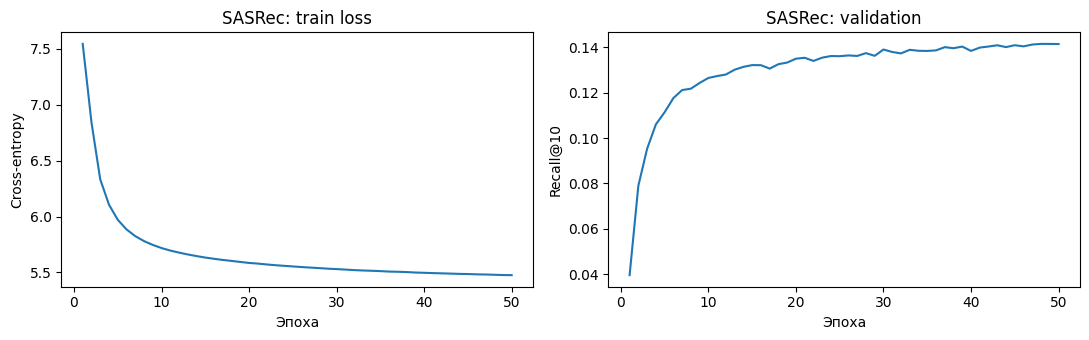

In [12]:
def sasrec_validation_fn(model):
    prediction = predict_sasrec(model, train_histories, validation_users, seen_matrix, popularity,
                                SASREC_PARAMETERS, nn_trained_items)
    return recall_at_k(prediction, targets, K)[0]

started = time.perf_counter()
sasrec_model, sasrec_history, sasrec_best_epoch = fit_sasrec(
    train_histories, SASREC_PARAMETERS, SASREC_PARAMETERS['max_epochs'],
    OUTPUT_DIR / 'sasrec_validation_best.pt', validation_fn=sasrec_validation_fn,
)
SASREC_VALIDATION_SECONDS = time.perf_counter() - started
sasrec_prediction = predict_sasrec(sasrec_model, train_histories, validation_users, seen_matrix,
                                  popularity, SASREC_PARAMETERS, nn_trained_items)
nn_score = register_validation(
    'sasrec', 'H3: порядок истории улучшает рекомендации; финальная модель', sasrec_prediction,
    SASREC_VALIDATION_SECONDS, {**SASREC_PARAMETERS, 'best_epoch': sasrec_best_epoch},
)
print('Лучшая эпоха:', sasrec_best_epoch)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(sasrec_history['epoch'], sasrec_history['train_loss'])
axes[0].set(title='SASRec: train loss', xlabel='Эпоха', ylabel='Cross-entropy')
axes[1].plot(sasrec_history['epoch'], sasrec_history['local_recall_at_10'])
axes[1].set(title='SASRec: validation', xlabel='Эпоха', ylabel='Recall@10')
plt.tight_layout()
plt.show()

## 9. Сравнение проведённых экспериментов

Все модели оценены на одном разбиении, с одинаковым target и фильтрацией просмотренного.
Таблица ниже содержит результаты текущего запуска. После сравнения финальным подходом остаётся SASRec.

In [13]:
results = pd.DataFrame(experiment_rows).sort_values(
    ['local_recall_at_10', 'model'], ascending=[False, True], kind='stable'
).reset_index(drop=True)
display(results[['model', 'local_recall_at_10', 'parameters', 'elapsed_seconds']])
results.to_csv(OUTPUT_DIR / 'experiments.csv', index=False)

,model,local_recall_at_10,parameters,elapsed_seconds
0,sasrec,0.141546,"{""batch_size"": 128, ""best_epoch"": 48, ""dropout"": 0.2, ""embedding_dim"": 64, ""gradient_clip"": 1.0,...",309.197
1,ease_l2_1000,0.065038,"{""regularization"": 1000.0}",6.479
2,ease_l2_3000,0.064884,"{""regularization"": 3000.0}",6.395
3,ease_l2_300,0.063336,"{""regularization"": 300.0}",6.527
4,ease_l2_10000,0.062299,"{""regularization"": 10000.0}",6.334
5,ease_l2_100,0.061258,"{""regularization"": 100.0}",6.439
6,itemknn,0.055767,"{""neighbors"": 100, ""shrinkage"": 10.0}",3.938
7,popularity,0.036167,{},1.717


## 10. Полное обучение финальной модели и сабмит

Сохраняем выбранное число эпох. Инициализируем SASRec заново с тем же seed и обучаем на всех доступных событиях.
Validation возвращается в обучение только на этом этапе. Для каждого пользователя из sample
получаем 10 различных фильмов и сохраняем исходный порядок пользователей.

`sasrec_validation_best.pt` содержит модель на train-части; **`sasrec_full.pt` — финальные веса для сабмита**.
Checkpoint хранит `state_dict`, параметры, порядок ID фильмов, число эпох, seed, версии и SHA-256 исходных данных.

In [14]:
full_train = relevant(events, CONFIG['train_min_rating'])
full_matrix = interaction_matrix(full_train)
full_seen = interaction_matrix(events)
full_popularity = popularity_scores(full_matrix)
full_histories = histories_from_events(full_train)
full_nn_mask = np.zeros(N_ITEMS, dtype=bool)
for sequence in full_histories.values():
    full_nn_mask[sequence] = True

sasrec_model.to('cpu')
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()
print(f'Обучение на полной истории: {sasrec_best_epoch} эпох')
full_sasrec_model, full_sasrec_history, _ = fit_sasrec(
    full_histories, SASREC_PARAMETERS, sasrec_best_epoch,
    OUTPUT_DIR / 'sasrec_full.pt', validation_fn=None,
)
final_predictions = predict_sasrec(
    full_sasrec_model, full_histories, sample['user_id'].tolist(), full_seen,
    full_popularity, SASREC_PARAMETERS, full_nn_mask,
)
submission = sample[['user_id']].copy()
submission['item_id'] = submission['user_id'].map(lambda uid: ' '.join(final_predictions[uid]))
SUBMISSION_PATH = OUTPUT_DIR / 'submission.csv'
submission.to_csv(SUBMISSION_PATH, index=False)
display(submission.head())
print(f'Сохранён {SUBMISSION_PATH}: {len(submission)} пользователей, {K} рекомендаций на каждого')

Обучение на полной истории: 48 эпох
Epoch 01/48: loss=7.5142; Recall@10=— (full refit); 3.2 с
Epoch 02/48: loss=6.6752; Recall@10=— (full refit); 3.2 с
Epoch 03/48: loss=6.2592; Recall@10=— (full refit); 3.1 с
Epoch 04/48: loss=6.0691; Recall@10=— (full refit); 3.1 с
Epoch 05/48: loss=5.9600; Recall@10=— (full refit); 3.2 с
Epoch 06/48: loss=5.8919; Recall@10=— (full refit); 3.1 с
Epoch 07/48: loss=5.8447; Recall@10=— (full refit); 3.1 с
Epoch 08/48: loss=5.8108; Recall@10=— (full refit); 3.2 с
Epoch 09/48: loss=5.7852; Recall@10=— (full refit); 3.2 с
Epoch 10/48: loss=5.7640; Recall@10=— (full refit); 3.1 с
Epoch 11/48: loss=5.7459; Recall@10=— (full refit); 3.2 с
Epoch 12/48: loss=5.7297; Recall@10=— (full refit); 3.2 с
Epoch 13/48: loss=5.7162; Recall@10=— (full refit); 3.1 с
Epoch 14/48: loss=5.7040; Recall@10=— (full refit); 3.2 с
Epoch 15/48: loss=5.6945; Recall@10=— (full refit); 3.2 с
Epoch 16/48: loss=5.6836; Recall@10=— (full refit); 3.2 с
Epoch 17/48: loss=5.6754; Recall@10=

,user_id,item_id
0,0,3002 213 1461 1527 2275 1171 1044 2454 3411 1160
1,1,1686 232 2338 2336 1868 3311 3656 1822 463 452
2,2,1687 2354 702 488 3035 570 2338 2185 1956 3539
3,3,2363 802 3013 2814 810 1223 2564 3035 1543 762
4,4,1545 802 1337 3035 1086 2814 2653 488 2185 3030


Сохранён outputs/submission.csv: 6040 пользователей, 10 рекомендаций на каждого


## 11. Сохранение результатов

В `outputs/` находятся финальный CSV, оба checkpoint, история эпох, таблица экспериментов и параметры запуска.
Дополнительно собирается `final_artifacts.zip` — его удобно скачать целиком из Kaggle.
Для GitHub достаточно этой тетрадки, исходных CSV и сохранённых результатов.

Число **0,2847** относится к уже полученному результату исходного сабмита. Новый CSV оценивается
после отправки в Kaggle. В отчёте сохраняется его SHA-256 и сравнение с исходным успешным CSV;
это сравнение информационное и не останавливает выполнение.

In [15]:
REFERENCE_PUBLIC_SCORES = {'itemknn': 0.0594, 'ease_l2_1000': 0.0860, 'sasrec': 0.2847}
REFERENCE_SUBMISSION_SHA256 = 'c6ef549014336f93ff099cd6e0fd85a806a0155fca5ec0c6a051999db1c7a443'
submission_hash = file_sha256(SUBMISSION_PATH)
run_info = {
    'final_model': 'sasrec', 'config': CONFIG, 'versions': VERSIONS, 'data_hashes': DATA_HASHES,
    'best_epoch': sasrec_best_epoch, 'local_recall_at_10': nn_score,
    'validation_results': results.to_dict(orient='records'),
    'submission_sha256': submission_hash,
    'reference_public_scores': REFERENCE_PUBLIC_SCORES,
    'reference_submission_sha256': REFERENCE_SUBMISSION_SHA256,
    'matches_reference_submission': submission_hash == REFERENCE_SUBMISSION_SHA256,
}
(OUTPUT_DIR / 'run_info.json').write_text(json.dumps(run_info, ensure_ascii=False, indent=2), encoding='utf-8')

artifact_names = [
    'submission.csv', 'sasrec_full.pt', 'sasrec_validation_best.pt',
    'sasrec_full.history.csv', 'sasrec_validation_best.history.csv', 'experiments.csv', 'run_info.json',
]
archive_path = OUTPUT_DIR / 'final_artifacts.zip'
with zipfile.ZipFile(archive_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for name in artifact_names:
        archive.write(OUTPUT_DIR / name, arcname=name)
print('Архив для скачивания:', archive_path)
print('CSV совпадает с исходным успешным сабмитом:', run_info['matches_reference_submission'])

Архив для скачивания: outputs/final_artifacts.zip
CSV совпадает с исходным успешным сабмитом: True


## 12. Итоги и журнал гипотез

Результаты исходного завершённого эксперимента:

| Этап | Проверяемая гипотеза | Локальный Recall@10 | Kaggle Recall@10 | Вывод |
|---|---|---:|---:|---|
| H0: популярность | Популярные фильмы дают точку отсчёта | 0,036167 | — | Получен стартовый бейзлайн |
| H1: ItemKNN | Сходство фильмов улучшает персонализацию | 0,055767 | 0,0594 | Качество выше популярности |
| H2: EASE | Совместно обученные связи фильм–фильм улучшают результат | 0,065038 | 0,0860 | Выбрана λ = 1000; пройден baseline_5 = 0,0821 |
| **H3: SASRec — финальная модель** | Порядок истории даёт дополнительный сигнал | **0,141546** | **0,2847** | Лучший результат проекта |

Для EASE проверены только пять значений λ: 100 → 0,061258; 300 → 0,063336;
1000 → 0,065038; 3000 → 0,064884; 10000 → 0,062299. Выбор сделан по validation.
Для SASRec использованы 50 эпох как верхняя граница; лучшей стала 48-я.
Финальная модель затем обучена на полной истории 48 эпох.

Персонализация последовательно улучшила локальную метрику. Наиболее сильный прирост дал SASRec,
учитывающий последовательность взаимодействий. Локальные значения и Kaggle score относятся к разным
наборам и не сравниваются напрямую. **Итоговый зафиксированный результат проекта — 0,2847 на Kaggle.**

Источники: [SASRec, Kang & McAuley](https://arxiv.org/abs/1808.09781),
[EASE, Steck](https://arxiv.org/abs/1905.03375),
[RePlay](https://github.com/sb-ai-lab/RePlay),
[соревнование](https://www.kaggle.com/competitions/hse-rec-sys-challenge-2026).